In [1]:

# Data analysis libraries
import pandas as pd
import numpy as np

# Data visualization library
import matplotlib.pyplot as plt

# Date and time handling
from datetime import datetime, timezone

# Display tables and outputs
from IPython.display import display

# File handling
import os
import re

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the retail orders dataset
df = pd.read_csv("retail-orders-raw.csv")

# Load the data dictionary
dictionary = pd.read_csv("retail-data-dictionary.csv")

# Display first five records
print("RETAIL ORDERS DATASET")
display(df.head())

print("\nDATA DICTIONARY")
display(dictionary)

# Display dataset information
print("\nDataset Shape:", df.shape)
print("Column Names:", df.columns.tolist())


RETAIL ORDERS DATASET


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.0,Paid
1,RT-1002,03/01/2026,Fresher,Bengaluru,Course Access,1,1499,0.0,paid
2,RT-1003,2026-01-05,student,Chennai,Course Access,1,1499,NaN,Pending
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid



DATA DICTIONARY


,column,data_type,business_definition,quality_rule
0,order_id,string,Unique order identifier,Required and unique
1,order_date,date,Date the customer placed the order,Required ISO date between 2025-01-01 and today
2,customer_segment,category,Commercial customer segment,Student Fresher or Professional after normaliz...
3,city,string,Customer billing city,Required non-empty text
4,category,category,Product family,Learning Kit Course Access or Mentor Session
5,quantity,integer,Units purchased,Whole number greater than zero
6,unit_price,decimal,Price per unit before discount,Non-negative INR amount
7,discount_pct,decimal,Percentage discount applied,Between 0 and 100; missing means zero only aft...
8,payment_status,category,Latest order settlement state,Paid Pending Failed or Refunded after normaliz...



Dataset Shape: (12, 9)
Column Names: ['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']


In [3]:
print("DATASET INFORMATION")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Order IDs:")
print(df["order_id"].duplicated().sum())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          12 non-null     object 
 1   order_date        11 non-null     object 
 2   customer_segment  12 non-null     object 
 3   city              11 non-null     object 
 4   category          12 non-null     object 
 5   quantity          12 non-null     object 
 6   unit_price        12 non-null     int64  
 7   discount_pct      11 non-null     float64
 8   payment_status    12 non-null     object 
dtypes: float64(1), int64(1), object(7)
memory usage: 996.0+ bytes

Missing Values:


,0
order_id,0
order_date,1
customer_segment,0
city,1
category,0
quantity,0
unit_price,0
discount_pct,1
payment_status,0



Duplicate Order IDs:
1


In [4]:
kpi_dictionary = pd.DataFrame([
    ["Total Orders", "Count of unique order IDs", "Order ID", "All orders", "Sales Manager", "Daily"],
    ["Paid Orders", "Count of orders with Paid status", "Order ID", "Payment status = Paid", "Sales Manager", "Daily"],
    ["Total Units Sold", "Sum of valid quantities", "Order", "Valid quantity", "Sales Manager", "Daily"],
    ["Gross Revenue", "Sum of unit price × quantity", "Order", "Valid sales records", "Sales Manager", "Daily"],
    ["Total Discount", "Sum of gross revenue × discount percentage", "Order", "Valid discount values", "Sales Manager", "Daily"],
    ["Net Revenue", "Gross revenue − total discount", "Order", "Valid sales records", "Sales Manager", "Daily"],
    ["Average Order Value", "Net revenue ÷ eligible paid orders", "Order", "Paid orders with valid revenue", "Sales Manager", "Daily"],
    ["Pending Orders", "Count of Pending orders", "Order ID", "Payment status = Pending", "Sales Manager", "Daily"],
    ["Failed Orders", "Count of Failed orders", "Order ID", "Payment status = Failed", "Sales Manager", "Daily"],
    ["Refunded Orders", "Count of Refunded orders", "Order ID", "Payment status = Refunded", "Sales Manager", "Daily"],
    ["Payment Success Rate", "Paid orders ÷ (Paid + Failed + Refunded) × 100", "Order ID", "Pending orders excluded", "Sales Manager", "Daily"],
    ["Category-wise Net Revenue", "Sum of net revenue for each category", "Category", "Valid sales records", "Sales Manager", "Daily"]
], columns=["KPI Name", "Formula / Definition", "Grain", "Filters", "Owner", "Refresh Cadence"])

display(kpi_dictionary)

,KPI Name,Formula / Definition,Grain,Filters,Owner,Refresh Cadence
0,Total Orders,Count of unique order IDs,Order ID,All orders,Sales Manager,Daily
1,Paid Orders,Count of orders with Paid status,Order ID,Payment status = Paid,Sales Manager,Daily
2,Total Units Sold,Sum of valid quantities,Order,Valid quantity,Sales Manager,Daily
3,Gross Revenue,Sum of unit price × quantity,Order,Valid sales records,Sales Manager,Daily
4,Total Discount,Sum of gross revenue × discount percentage,Order,Valid discount values,Sales Manager,Daily
5,Net Revenue,Gross revenue − total discount,Order,Valid sales records,Sales Manager,Daily
6,Average Order Value,Net revenue ÷ eligible paid orders,Order,Paid orders with valid revenue,Sales Manager,Daily
7,Pending Orders,Count of Pending orders,Order ID,Payment status = Pending,Sales Manager,Daily
8,Failed Orders,Count of Failed orders,Order ID,Payment status = Failed,Sales Manager,Daily
9,Refunded Orders,Count of Refunded orders,Order ID,Payment status = Refunded,Sales Manager,Daily


In [5]:
# Save KPI Dictionary
kpi_dictionary.to_csv("kpi_dictionary.csv", index=False)

print("KPI Dictionary saved successfully!")

display(kpi_dictionary)

KPI Dictionary saved successfully!


,KPI Name,Formula / Definition,Grain,Filters,Owner,Refresh Cadence
0,Total Orders,Count of unique order IDs,Order ID,All orders,Sales Manager,Daily
1,Paid Orders,Count of orders with Paid status,Order ID,Payment status = Paid,Sales Manager,Daily
2,Total Units Sold,Sum of valid quantities,Order,Valid quantity,Sales Manager,Daily
3,Gross Revenue,Sum of unit price × quantity,Order,Valid sales records,Sales Manager,Daily
4,Total Discount,Sum of gross revenue × discount percentage,Order,Valid discount values,Sales Manager,Daily
5,Net Revenue,Gross revenue − total discount,Order,Valid sales records,Sales Manager,Daily
6,Average Order Value,Net revenue ÷ eligible paid orders,Order,Paid orders with valid revenue,Sales Manager,Daily
7,Pending Orders,Count of Pending orders,Order ID,Payment status = Pending,Sales Manager,Daily
8,Failed Orders,Count of Failed orders,Order ID,Payment status = Failed,Sales Manager,Daily
9,Refunded Orders,Count of Refunded orders,Order ID,Payment status = Refunded,Sales Manager,Daily


In [6]:
print("Available Dataset Columns:")
print(df.columns.tolist())

print("\nPayment Status Values:")
print(df["payment_status"].unique())

Available Dataset Columns:
['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']

Payment Status Values:
['Paid' 'paid' 'Pending' 'Failed' 'Refunded']


In [7]:

# STEP 6: KPI CALCULATIONS

import pandas as pd
import numpy as np

# Create a working copy
data = df.copy()

# Remove duplicate order records
data = data.drop_duplicates(subset="order_id", keep="first")

# Normalize payment status
data["payment_status"] = (
    data["payment_status"].astype(str).str.strip().str.lower()
)

# Convert numerical columns
data["quantity"] = pd.to_numeric(data["quantity"], errors="coerce")
data["unit_price"] = pd.to_numeric(data["unit_price"], errors="coerce")
data["discount_pct"] = pd.to_numeric(data["discount_pct"], errors="coerce")

# Identify valid sales records
valid_sales = data[
    (data["quantity"] > 0) &
    (data["unit_price"] >= 0) &
    (data["discount_pct"].between(0, 100)) &
    (data["discount_pct"].notna())
].copy()

# Calculate revenue
valid_sales["gross_revenue"] = (
    valid_sales["quantity"] * valid_sales["unit_price"]
)

valid_sales["discount_amount"] = (
    valid_sales["gross_revenue"] *
    valid_sales["discount_pct"] / 100
)

valid_sales["net_revenue"] = (
    valid_sales["gross_revenue"] -
    valid_sales["discount_amount"]
)

# Calculate KPI values
total_orders = data["order_id"].nunique()

paid_orders = (data["payment_status"] == "paid").sum()

total_units = valid_sales["quantity"].sum()

gross_revenue = valid_sales["gross_revenue"].sum()

total_discount = valid_sales["discount_amount"].sum()

net_revenue = valid_sales["net_revenue"].sum()

eligible_paid = valid_sales[
    valid_sales["payment_status"] == "paid"
]

average_order_value = (
    eligible_paid["net_revenue"].sum() /
    len(eligible_paid)
    if len(eligible_paid) > 0 else 0
)

pending_orders = (data["payment_status"] == "pending").sum()

failed_orders = (data["payment_status"] == "failed").sum()

refunded_orders = (data["payment_status"] == "refunded").sum()

denominator = paid_orders + failed_orders + refunded_orders

payment_success_rate = (
    paid_orders / denominator * 100
    if denominator > 0 else 0
)

# Create KPI results table
kpi_results = pd.DataFrame({
    "KPI Name": [
        "Total Orders",
        "Paid Orders",
        "Total Units Sold",
        "Gross Revenue",
        "Total Discount",
        "Net Revenue",
        "Average Order Value",
        "Pending Orders",
        "Failed Orders",
        "Refunded Orders",
        "Payment Success Rate",
        "Category-wise Net Revenue"
    ],
    "KPI Value": [
        total_orders,
        paid_orders,
        total_units,
        gross_revenue,
        total_discount,
        net_revenue,
        average_order_value,
        pending_orders,
        failed_orders,
        refunded_orders,
        payment_success_rate,
        "See category breakdown below"
    ]
})

print("========== KPI RESULTS ==========")
display(kpi_results)

# Category-wise revenue
category_revenue = valid_sales.groupby("category")[
    "net_revenue"
].sum().reset_index()

print("\n========== CATEGORY-WISE NET REVENUE ==========")
display(category_revenue)

# Save KPI results
kpi_results.to_csv("kpi_results.csv", index=False)
category_revenue.to_csv("category_revenue.csv", index=False)

print("\nKPI calculations completed successfully!")


========== KPI RESULTS ==========


,KPI Name,KPI Value
0,Total Orders,11
1,Paid Orders,7
2,Total Units Sold,11.0
3,Gross Revenue,11289.0
4,Total Discount,729.35
5,Net Revenue,10559.65
6,Average Order Value,1402.47
7,Pending Orders,2
8,Failed Orders,1
9,Refunded Orders,1



========== CATEGORY-WISE NET REVENUE ==========


,category,net_revenue
0,Course Access,4047.30
1,Learning Kit,4514.35
2,Mentor Session,1998.00



KPI calculations completed successfully!


In [8]:

# STEP 7: DATA QUALITY VALIDATION

print("========== DATA QUALITY REPORT ==========")

# 1. Missing values
print("\n1. Missing Values")
display(data.isnull().sum())

# 2. Duplicate Order IDs
print("\n2. Duplicate Order IDs")
print(data["order_id"].duplicated().sum())

# 3. Invalid quantities
print("\n3. Invalid Quantities")
print((data["quantity"] <= 0).sum())

# 4. Invalid unit prices
print("\n4. Invalid Unit Prices")
print((data["unit_price"] < 0).sum())

# 5. Invalid discount percentages
print("\n5. Invalid Discounts")
print((~data["discount_pct"].between(0, 100)).sum())

# 6. Invalid payment statuses
print("\n6. Invalid Payment Status")
valid_status = ["paid", "pending", "failed", "refunded"]

print((~data["payment_status"].isin(valid_status)).sum())

# 7. Invalid dates
print("\n7. Invalid Order Dates")
dates = pd.to_datetime(data["order_date"], errors="coerce")
print(dates.isna().sum())

print("\nDATA QUALITY VALIDATION COMPLETED!")


========== DATA QUALITY REPORT ==========

1. Missing Values


,0
order_id,0
order_date,1
customer_segment,0
city,1
category,0
quantity,1
unit_price,0
discount_pct,1
payment_status,0



2. Duplicate Order IDs
0

3. Invalid Quantities
1

4. Invalid Unit Prices
0

5. Invalid Discounts
2

6. Invalid Payment Status
0

7. Invalid Order Dates
3

DATA QUALITY VALIDATION COMPLETED!


In [9]:

# STEP 8: DATA QUALITY ISSUE ANALYSIS

quality_report = pd.DataFrame([
    ["Completeness", "Missing Values", data.isnull().sum().sum()],
    ["Uniqueness", "Duplicate Order IDs", data["order_id"].duplicated().sum()],
    ["Validity", "Invalid Quantities", (data["quantity"] <= 0).sum()],
    ["Validity", "Invalid Unit Prices", (data["unit_price"] < 0).sum()],
    ["Validity", "Invalid Discounts",
     (~data["discount_pct"].between(0, 100)).sum()],
    ["Consistency", "Invalid Payment Status",
     (~data["payment_status"].isin(
         ["paid", "pending", "failed", "refunded"]
     )).sum()],
    ["Validity", "Invalid Order Dates",
     pd.to_datetime(data["order_date"], errors="coerce").isna().sum()]
], columns=["Quality Dimension", "Issue", "Number of Records"])

quality_report["Result"] = quality_report["Number of Records"].apply(
    lambda x: "PASS" if x == 0 else "NEEDS ATTENTION"
)

print("========== DATA QUALITY ISSUE ANALYSIS ==========")
display(quality_report)

# Save report
quality_report.to_csv("data_quality_issues.csv", index=False)

print("Data quality issue analysis saved successfully!")


========== DATA QUALITY ISSUE ANALYSIS ==========


,Quality Dimension,Issue,Number of Records,Result
0,Completeness,Missing Values,4,NEEDS ATTENTION
1,Uniqueness,Duplicate Order IDs,0,PASS
2,Validity,Invalid Quantities,1,NEEDS ATTENTION
3,Validity,Invalid Unit Prices,0,PASS
4,Validity,Invalid Discounts,2,NEEDS ATTENTION
5,Consistency,Invalid Payment Status,0,PASS
6,Validity,Invalid Order Dates,3,NEEDS ATTENTION


Data quality issue analysis saved successfully!


In [10]:

# STEP 9: DATA QUALITY REPORT

total_records = len(data)
total_checks = len(quality_report)
passed_checks = (quality_report["Result"] == "PASS").sum()
failed_checks = (quality_report["Result"] == "NEEDS ATTENTION").sum()

total_issues = quality_report["Number of Records"].sum()

print("======================================")
print("       RETAIL DATA QUALITY REPORT")
print("======================================")

print("Total Records:", total_records)
print("Total Quality Checks:", total_checks)
print("Passed Checks:", passed_checks)
print("Checks Needing Attention:", failed_checks)
print("Total Data Quality Issues:", total_issues)

print("\nOVERALL QUALITY STATUS:")

if failed_checks == 0:
    print("GOOD - All quality checks passed")
else:
    print("REVIEW REQUIRED - Some issues were identified")

print("\nDETAILED QUALITY REPORT")
display(quality_report)

# Save final report
report_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Quality Checks",
        "Passed Checks",
        "Checks Needing Attention",
        "Total Data Quality Issues"
    ],
    "Value": [
        total_records,
        total_checks,
        passed_checks,
        failed_checks,
        total_issues
    ]
})

report_summary.to_csv("final_data_quality_report.csv", index=False)

print("\nFinal Data Quality Report saved successfully!")


       RETAIL DATA QUALITY REPORT
Total Records: 11
Total Quality Checks: 7
Passed Checks: 3
Checks Needing Attention: 4
Total Data Quality Issues: 10

OVERALL QUALITY STATUS:
REVIEW REQUIRED - Some issues were identified

DETAILED QUALITY REPORT


,Quality Dimension,Issue,Number of Records,Result
0,Completeness,Missing Values,4,NEEDS ATTENTION
1,Uniqueness,Duplicate Order IDs,0,PASS
2,Validity,Invalid Quantities,1,NEEDS ATTENTION
3,Validity,Invalid Unit Prices,0,PASS
4,Validity,Invalid Discounts,2,NEEDS ATTENTION
5,Consistency,Invalid Payment Status,0,PASS
6,Validity,Invalid Order Dates,3,NEEDS ATTENTION



Final Data Quality Report saved successfully!


In [11]:
import matplotlib.pyplot as plt
import pandas as pd

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


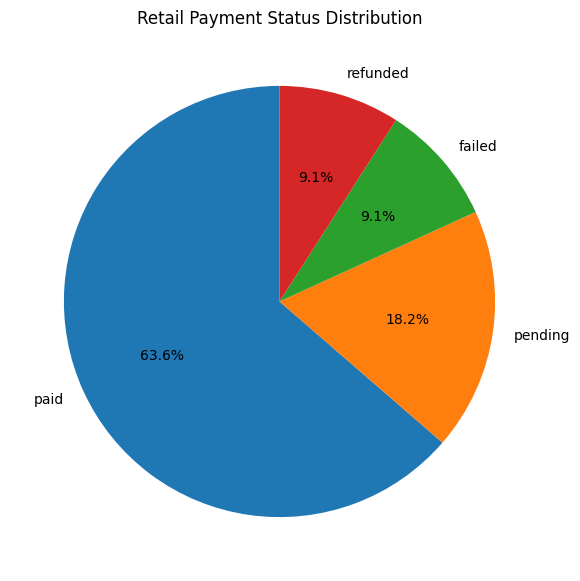

In [12]:

# PAYMENT STATUS PIE CHART

payment_counts = data["payment_status"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Retail Payment Status Distribution")
plt.show()


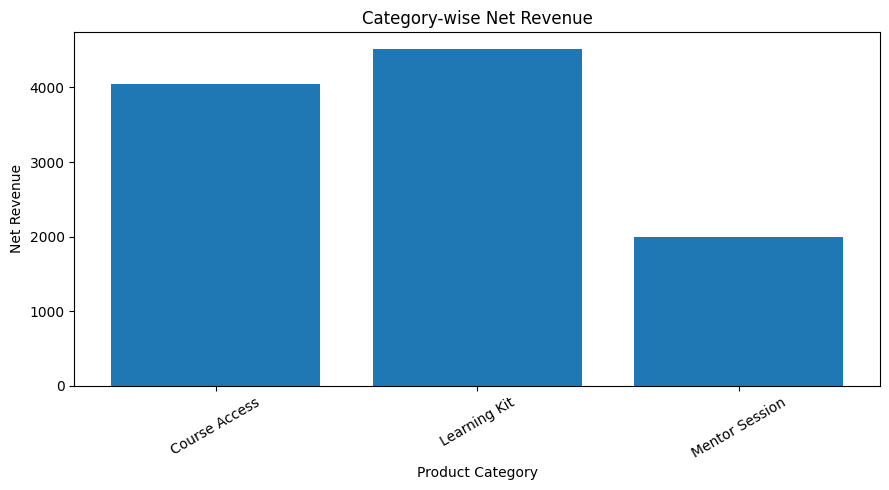

In [13]:

# CATEGORY-WISE NET REVENUE

plt.figure(figsize=(9, 5))

plt.bar(
    category_revenue["category"],
    category_revenue["net_revenue"]
)

plt.title("Category-wise Net Revenue")
plt.xlabel("Product Category")
plt.ylabel("Net Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


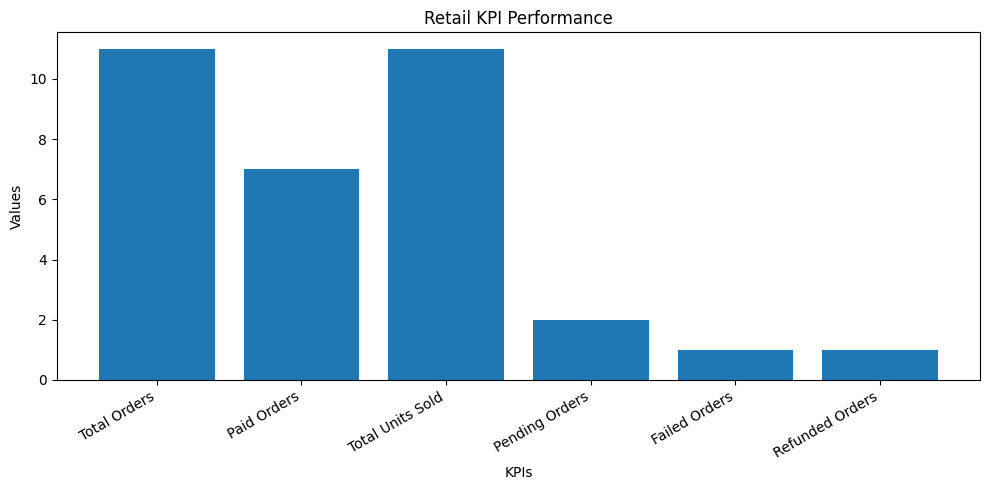

In [14]:

# KPI PERFORMANCE CHART

numeric_kpis = kpi_results[
    kpi_results["KPI Name"].isin([
        "Total Orders",
        "Paid Orders",
        "Total Units Sold",
        "Pending Orders",
        "Failed Orders",
        "Refunded Orders"
    ])
].copy()

numeric_kpis["KPI Value"] = pd.to_numeric(
    numeric_kpis["KPI Value"]
)

plt.figure(figsize=(10, 5))

plt.bar(
    numeric_kpis["KPI Name"],
    numeric_kpis["KPI Value"]
)

plt.title("Retail KPI Performance")
plt.xlabel("KPIs")
plt.ylabel("Values")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


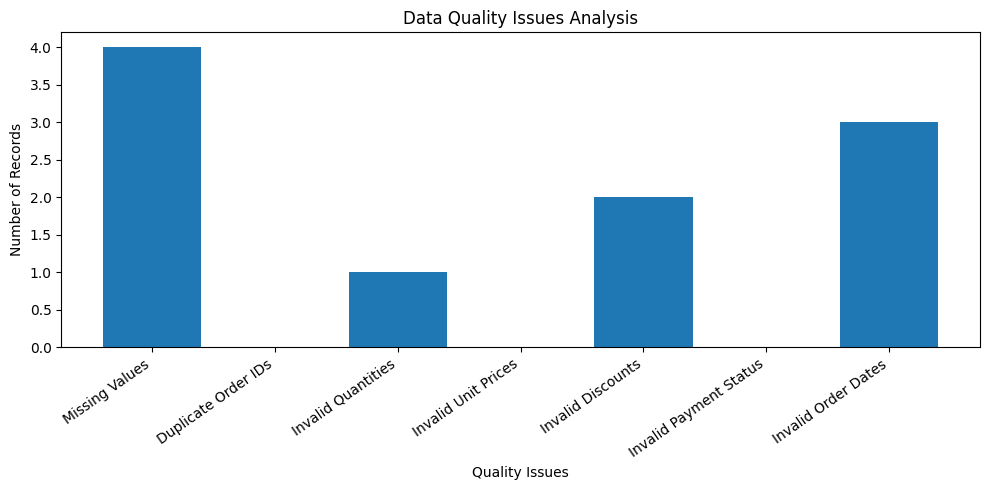

In [15]:

# DATA QUALITY ISSUES CHART

plt.figure(figsize=(10, 5))

plt.bar(
    quality_report["Issue"],
    quality_report["Number of Records"]
)

plt.title("Data Quality Issues Analysis")
plt.xlabel("Quality Issues")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [16]:

# STEP 11: FINAL PROJECT SUMMARY

print("=" * 55)
print("       RETAIL KPI & DATA QUALITY PROJECT")
print("=" * 55)

print("\n1. DATASET INFORMATION")
print("Total Records:", len(data))
print("Total Columns:", len(data.columns))

print("\n2. KPI SUMMARY")
print("Total Orders:", total_orders)
print("Paid Orders:", paid_orders)
print("Total Units Sold:", total_units)
print("Gross Revenue:", round(gross_revenue, 2))
print("Total Discount:", round(total_discount, 2))
print("Net Revenue:", round(net_revenue, 2))
print("Average Order Value:", round(average_order_value, 2))
print("Payment Success Rate:", round(payment_success_rate, 2), "%")

print("\n3. DATA QUALITY SUMMARY")
print("Total Quality Checks:", total_checks)
print("Passed Checks:", passed_checks)
print("Checks Needing Attention:", failed_checks)
print("Total Issues:", total_issues)

print("\n4. PROJECT OUTPUT FILES")
print("1. kpi_dictionary.csv")
print("2. kpi_results.csv")
print("3. category_revenue.csv")
print("4. data_quality_issues.csv")
print("5. final_data_quality_report.csv")

print("\nPROJECT SUMMARY GENERATED SUCCESSFULLY!")
print("=" * 55)


       RETAIL KPI & DATA QUALITY PROJECT

1. DATASET INFORMATION
Total Records: 11
Total Columns: 9

2. KPI SUMMARY
Total Orders: 11
Paid Orders: 7
Total Units Sold: 11.0
Gross Revenue: 11289.0
Total Discount: 729.35
Net Revenue: 10559.65
Average Order Value: 1402.47
Payment Success Rate: 77.78 %

3. DATA QUALITY SUMMARY
Total Quality Checks: 7
Passed Checks: 3
Checks Needing Attention: 4
Total Issues: 10

4. PROJECT OUTPUT FILES
1. kpi_dictionary.csv
2. kpi_results.csv
3. category_revenue.csv
4. data_quality_issues.csv
5. final_data_quality_report.csv

PROJECT SUMMARY GENERATED SUCCESSFULLY!


In [17]:
import zipfile

files_to_export = [
    "kpi_dictionary.csv",
    "kpi_results.csv",
    "category_revenue.csv",
    "data_quality_issues.csv",
    "final_data_quality_report.csv"
]

with zipfile.ZipFile("Retail_KPI_Project.zip", "w") as zipf:
    for file in files_to_export:
        zipf.write(file)

print("All project files exported successfully!")

All project files exported successfully!


In [18]:
from google.colab import files
files.download("Retail_KPI_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>